In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.svm import SVC
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.naive_bayes import GaussianNB

from sklearn.metrics import accuracy_score, classification_report, confusion_matrix

In [2]:
X_train = pd.read_excel("X_train_preprocessed.xlsx")
X_test = pd.read_excel("X_test_preprocessed.xlsx")
y_train = pd.read_excel("y_train.xlsx").values.ravel()
y_test = pd.read_excel("y_test.xlsx").values.ravel()

X_predict = pd.read_excel("X_predict_preprocessed.xlsx")

In [3]:
def group_position(pos):
    if pos <= 3:
        return "Top 3"
    elif pos <= 10:
        return "Top 10"
    else:
        return "Others"

y_train = pd.Series(y_train).apply(group_position)
y_test = pd.Series(y_test).apply(group_position)

In [4]:
print("X_train:", X_train.shape)
print("X_test:", X_test.shape)
print("y_train:", y_train.shape)
print("y_test:", y_test.shape)
print("X_predict:", X_predict.shape)

print("\nTraining target distribution:")
print(y_train.value_counts())

X_train: (479, 66)
X_test: (479, 66)
y_train: (479,)
y_test: (479,)
X_predict: (22, 66)

Training target distribution:
Others    239
Top 10    168
Top 3      72
Name: count, dtype: int64


In [5]:
def run_evaluate_model(model, name):
    model.fit(X_train, y_train)
    y_pred = model.predict(X_test)

    acc = accuracy_score(y_test, y_pred)

    print("\n==============================")
    print(name)
    print("==============================")
    print("Accuracy:", acc)
    print(classification_report(y_test, y_pred, zero_division=0))

    cm = confusion_matrix(y_test, y_pred)
    plt.figure(figsize=(6,5))
    sns.heatmap(cm, annot=True, fmt="d", cmap="Blues")
    plt.title(f"Confusion Matrix - {name}")
    plt.xlabel("Predicted")
    plt.ylabel("Actual")
    plt.show()

    return acc


Logistic Regression
Accuracy: 0.6701461377870563
              precision    recall  f1-score   support

      Others       0.77      0.75      0.76       239
      Top 10       0.58      0.51      0.54       168
       Top 3       0.57      0.76      0.65        72

    accuracy                           0.67       479
   macro avg       0.64      0.68      0.65       479
weighted avg       0.67      0.67      0.67       479



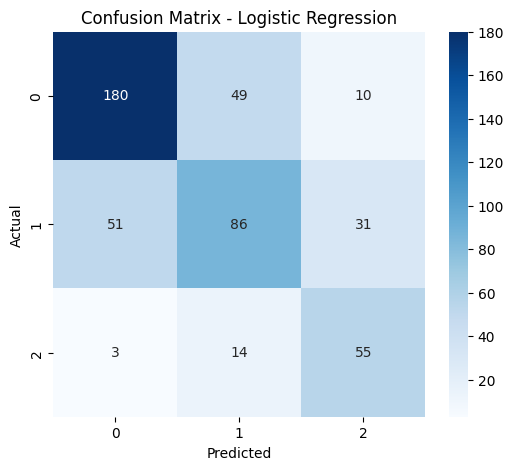

In [6]:
from sklearn.multiclass import OneVsRestClassifier

log_reg = OneVsRestClassifier(
    LogisticRegression(
        max_iter=20000,
        solver="liblinear",
        class_weight="balanced"
    )
)

acc_lr = run_evaluate_model(log_reg, "Logistic Regression")

c:\Users\Administrator\AppData\Local\Python\pythoncore-3.14-64\Lib\site-packages\joblib\externals\loky\backend\context.py:131: UserWarning: Could not find the number of physical cores for the following reason:
[WinError 2] The system cannot find the file specified
Returning the number of logical cores instead. You can silence this warning by setting LOKY_MAX_CPU_COUNT to the number of cores you want to use.
  warnings.warn(
  File "c:\Users\Administrator\AppData\Local\Python\pythoncore-3.14-64\Lib\site-packages\joblib\externals\loky\backend\context.py", line 247, in _count_physical_cores
    cpu_count_physical = _count_physical_cores_win32()
  File "c:\Users\Administrator\AppData\Local\Python\pythoncore-3.14-64\Lib\site-packages\joblib\externals\loky\backend\context.py", line 299, in _count_physical_cores_win32
    cpu_info = subprocess.run(
        "wmic CPU Get NumberOfCores /Format:csv".split(),
        capture_output=True,
        text=True,
    )
  File "c:\Users\Administrator\App


KNN
Accuracy: 0.5741127348643006
              precision    recall  f1-score   support

      Others       0.64      0.80      0.71       239
      Top 10       0.45      0.43      0.44       168
       Top 3       0.62      0.14      0.23        72

    accuracy                           0.57       479
   macro avg       0.57      0.46      0.46       479
weighted avg       0.57      0.57      0.54       479



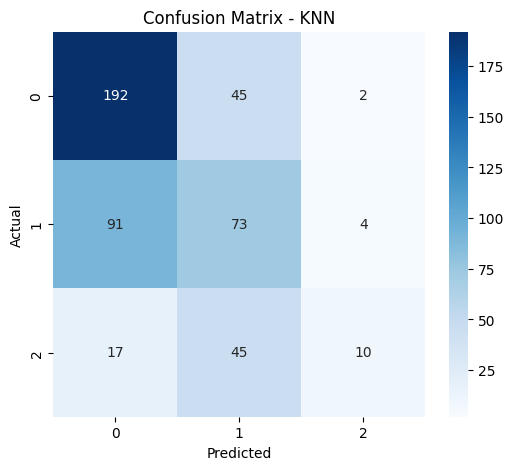

In [7]:
knn = KNeighborsClassifier(n_neighbors=5)

acc_knn = run_evaluate_model(knn, "KNN")


Support Vector Machine
Accuracy: 0.4989561586638831
              precision    recall  f1-score   support

      Others       0.50      1.00      0.67       239
      Top 10       0.00      0.00      0.00       168
       Top 3       0.00      0.00      0.00        72

    accuracy                           0.50       479
   macro avg       0.17      0.33      0.22       479
weighted avg       0.25      0.50      0.33       479



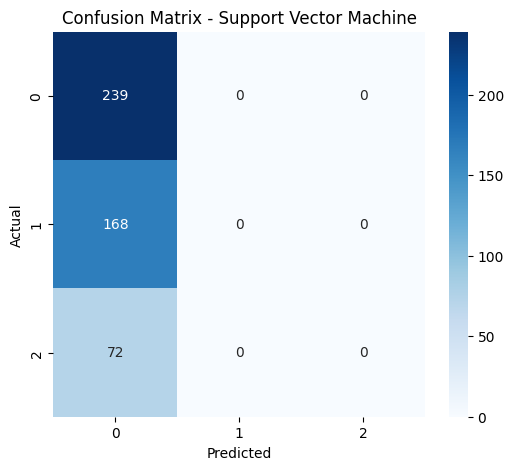

In [8]:
svm = SVC()

acc_svm = run_evaluate_model(svm, "Support Vector Machine")


Decision Tree
Accuracy: 0.55741127348643
              precision    recall  f1-score   support

      Others       0.69      0.57      0.63       239
      Top 10       0.45      0.55      0.49       168
       Top 3       0.51      0.53      0.52        72

    accuracy                           0.56       479
   macro avg       0.55      0.55      0.55       479
weighted avg       0.58      0.56      0.56       479



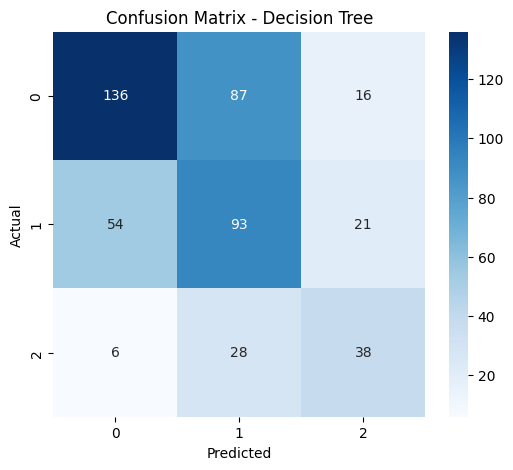

In [9]:
dt = DecisionTreeClassifier(random_state=42)

acc_dt = run_evaluate_model(dt, "Decision Tree")


Random Forest
Accuracy: 0.6868475991649269
              precision    recall  f1-score   support

      Others       0.76      0.76      0.76       239
      Top 10       0.57      0.61      0.59       168
       Top 3       0.73      0.61      0.67        72

    accuracy                           0.69       479
   macro avg       0.69      0.66      0.67       479
weighted avg       0.69      0.69      0.69       479



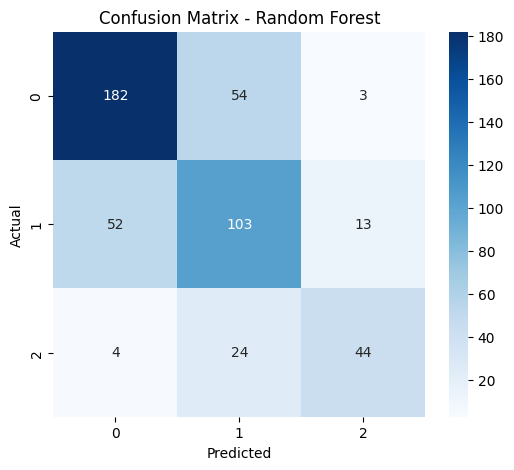

In [10]:
rf = RandomForestClassifier(random_state=42)

acc_rf = run_evaluate_model(rf, "Random Forest")


Naive Bayes
Accuracy: 0.5198329853862212
              precision    recall  f1-score   support

      Others       0.73      0.59      0.65       239
      Top 10       0.35      0.24      0.28       168
       Top 3       0.40      0.94      0.56        72

    accuracy                           0.52       479
   macro avg       0.49      0.59      0.50       479
weighted avg       0.54      0.52      0.51       479



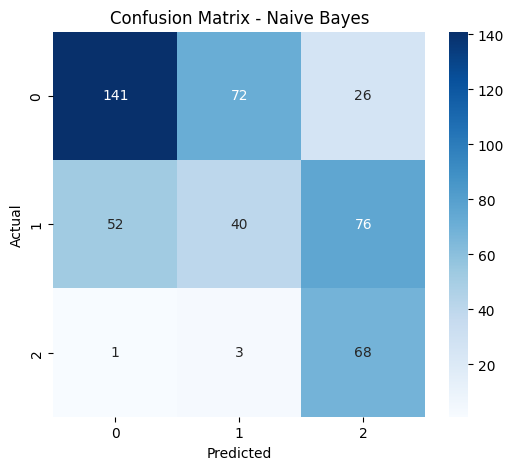

In [11]:
nb = GaussianNB()

acc_nb = run_evaluate_model(nb, "Naive Bayes")

In [12]:
results_df = pd.DataFrame({
    "Model": [
        "Logistic Regression",
        "KNN",
        "Support Vector Machine",
        "Decision Tree",
        "Random Forest",
        "Naive Bayes"
    ],
    "Accuracy": [
        acc_lr,
        acc_knn,
        acc_svm,
        acc_dt,
        acc_rf,
        acc_nb
    ]
}).sort_values(by="Accuracy", ascending=False)

results_df

,Model,Accuracy
4,Random Forest,0.686848
0,Logistic Regression,0.670146
1,KNN,0.574113
3,Decision Tree,0.557411
5,Naive Bayes,0.519833
2,Support Vector Machine,0.498956


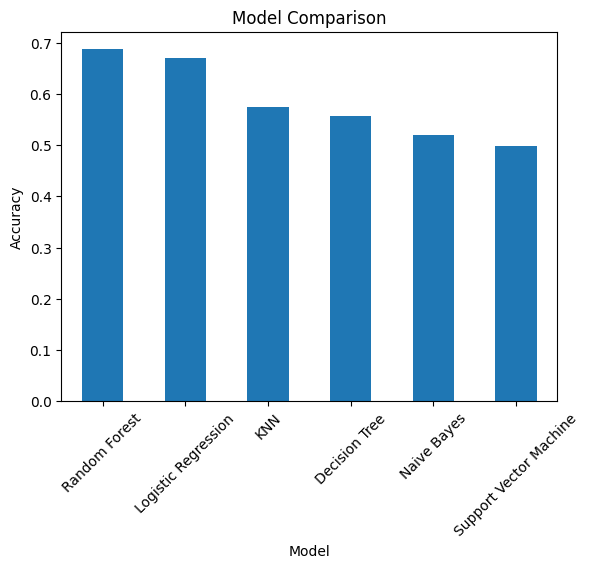

In [13]:
results_df.plot(x="Model", y="Accuracy", kind="bar", legend=False)
plt.title("Model Comparison")
plt.ylabel("Accuracy")
plt.xticks(rotation=45)
plt.show()

In [14]:
best_model_name = results_df.iloc[0]["Model"]

if best_model_name == "Logistic Regression":
    best_model = log_reg
elif best_model_name == "KNN":
    best_model = knn
elif best_model_name == "Support Vector Machine":
    best_model = svm
elif best_model_name == "Decision Tree":
    best_model = dt
elif best_model_name == "Random Forest":
    best_model = rf
else:
    best_model = nb

print("Best Model:", best_model_name)

Best Model: Random Forest


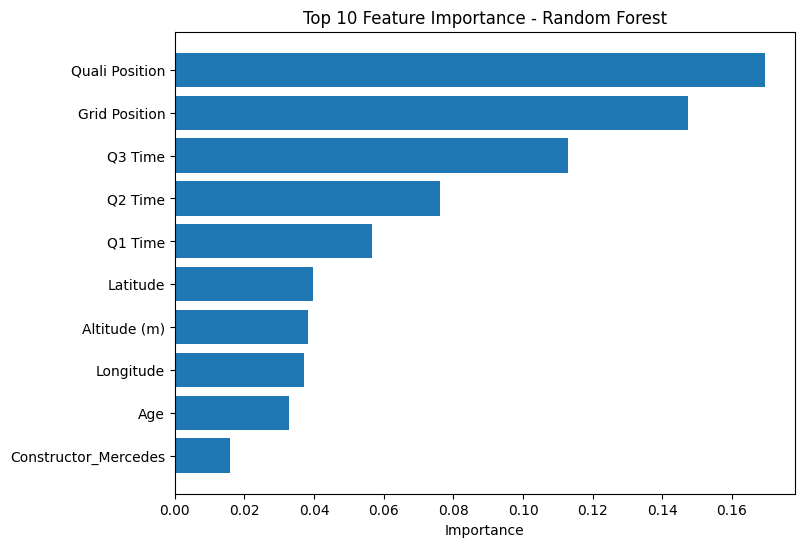

In [15]:
importances = rf.feature_importances_
indices = np.argsort(importances)[-10:]

plt.figure(figsize=(8,6))
plt.barh(range(len(indices)), importances[indices])
plt.yticks(range(len(indices)), X_train.columns[indices])
plt.title("Top 10 Feature Importance - Random Forest")
plt.xlabel("Importance")
plt.show()

In [16]:
df_2026 = pd.read_excel("F1_dataset_2024-2026.xlsx")

drivers = df_2026[df_2026["Year"] == 2026]["Driver"].reset_index(drop=True)

pred_2026 = best_model.predict(X_predict)

drivers = drivers.iloc[: len(pred_2026)].reset_index(drop=True)

pred_2026_df = pd.DataFrame({
    "Driver": drivers,
    "Predicted Group": pred_2026
})

pred_2026_df.to_excel("predicted_2026_positions_with_names.xlsx", index=False)

In [17]:
pred_2026_df.head()

,Driver,Predicted Group
0,George Russell,Top 3
1,Kimi Antonelli,Top 3
2,Charles Leclerc,Top 3
3,Lewis Hamilton,Top 10
4,Lando Norris,Top 10


In [18]:
import joblib

joblib.dump(best_model, "classification_model.pkl")
joblib.dump(list(X_train.columns), "classification_features.pkl")

print("✅ classification_model.pkl and classification_features.pkl saved!")


✅ classification_model.pkl and classification_features.pkl saved!
